In [33]:
import pandas as pd
df = pd.read_csv ('/kaggle/input/datasets/luthfimuthathohirin/global-ai-semiconductor-supply-chain-telemetry/global_ai_semiconductor_supply_chain_enriched_2026.csv')

In [34]:
df.shape

(10000, 29)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   facility_id                       10000 non-null  object 
 1   company_name                      10000 non-null  object 
 2   country_location                  10000 non-null  object 
 3   facility_type                     10000 non-null  object 
 4   process_node_nm                   10000 non-null  object 
 5   wafer_size_mm                     10000 non-null  int64  
 6   monthly_capacity_wafers           10000 non-null  int64  
 7   capacity_utilization_pct          10000 non-null  float64
 8   die_yield_pct                     10000 non-null  float64
 9   defect_density_per_cm2            10000 non-null  float64
 10  lithography_technology            10000 non-null  object 
 11  lithography_tool_supplier         10000 non-null  object 
 12  litho

In [36]:
summary = df.groupby('country_location').agg(
    Total_Capacity=('monthly_capacity_wafers','sum'),
    Avg_Vulnerability=('supply_chain_vulnerability_score','mean'),
    Avg_Backlog=('packaging_backlog_weeks','mean')
).reset_index()

In [37]:
summary_sorted = summary.sort_values(by= 'Total_Capacity', ascending=False)
display(summary_sorted)

,country_location,Total_Capacity,Avg_Vulnerability,Avg_Backlog
6,South Korea,178153857,60.044020,21.260314
8,USA,148466878,47.466183,22.003574
7,Taiwan,133976905,71.036355,22.153108
3,Japan,33163207,52.256519,21.330370
1,Germany,22907496,47.046889,20.566667
5,Singapore,13645484,44.715034,17.326531
0,China,7162268,59.894565,8.836957
2,Ireland,6665208,48.281013,24.481013
4,Netherlands,6005929,49.187433,22.444776


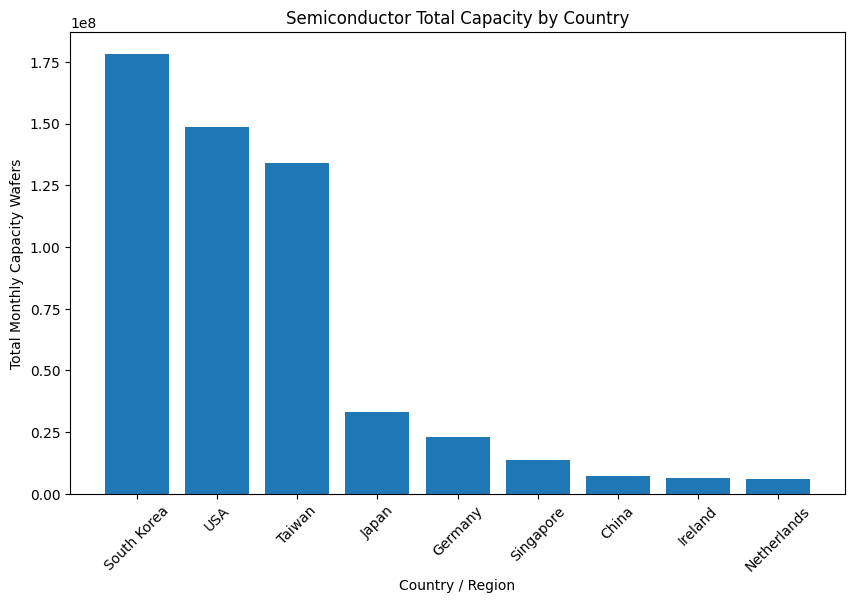

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.bar(summary_sorted['country_location'], summary_sorted['Total_Capacity'])
plt.xlabel('Country / Region')
plt.ylabel('Total Monthly Capacity Wafers')
plt.title('Semiconductor Total Capacity by Country')
plt.xticks(rotation=45)
plt.show()

In [42]:
export_summary = df.groupby ('export_restriction_tier').agg(
    Avg_Backlog_Weeks = ('packaging_backlog_weeks','mean')
).reset_index()

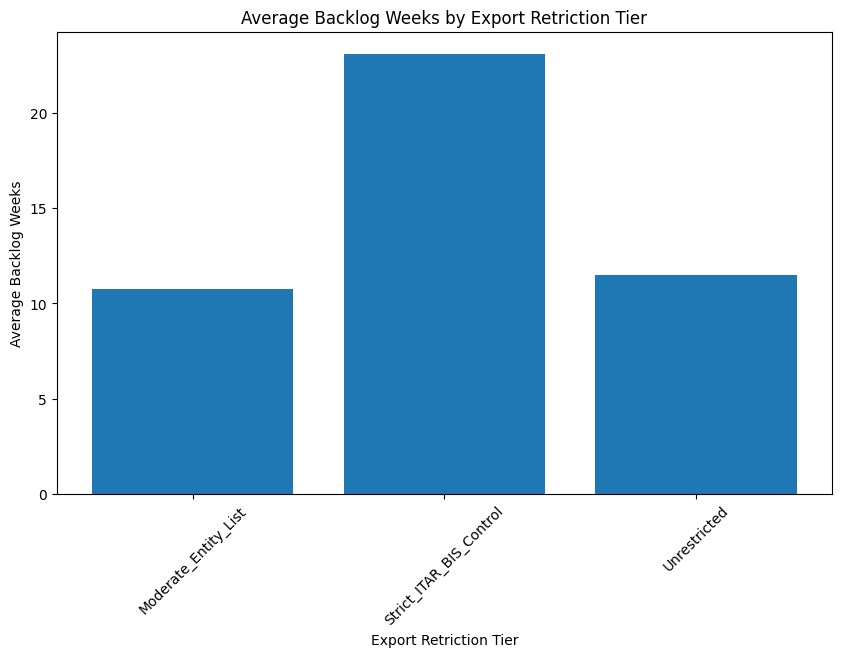

In [44]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.bar(export_summary['export_restriction_tier'],export_summary['Avg_Backlog_Weeks'])
plt.xlabel('Export Retriction Tier')
plt.ylabel('Average Backlog Weeks')
plt.title('Average Backlog Weeks by Export Retriction Tier')
plt.xticks(rotation=45)
plt.show()
